# ML evaluation: real vs fake with simple features

**Question:** how much do the forensic features (spectral, RGB, NPR) add to a model that only sees basic image statistics?

**Method:** start from 4 basic statistics (baseline), then add one family of features at a time. Every model is a standardized logistic regression. The data is split **by pairs**: a real image and its fake twin always stay together.

**Contents:** 1. Data and split · 2. Results table · 3. Stability over random splits · 4. Figures · 5. Conclusions and limits

## 1. Data and split

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.ml_pipeline import (load_features, make_pair_split, train_logistic, predict_scores,
                             run_ablation, PROGRESSION_GROUPS)

BLUE, ORANGE = "#156082", "#E97132"                       # real, fake
FAMILY_COLORS = {"baseline": "#7F7F7F", "spectral": "#4EA72E", "rgb": "#A02B93", "npr": "#C9A227"}

In [2]:
table, families = load_features()
print(f"{table['pair_id'].nunique()} pairs, {len(table)} images")
print({name: len(columns) for name, columns in families.items()}, "features per family")

train, test = make_pair_split(table, test_size=0.3, seed=0)
print(f"train: {len(train)} images, test: {len(test)} images")

16 pairs dropped: a feature is undefined for one of their images.
984 pairs, 1968 images
{'baseline': 4, 'spectral': 10, 'rgb': 22, 'npr': 180} features per family
train: 1378 images, test: 590 images


*A real image and its fake twin always stay on the same side of the split. 16 pairs were removed because a real crop is completely white, so its spectrum is undefined.*

## 2. Results table
Rows starting with `+` keep all previous families; rows ending with `alone` use a single family.

In [3]:
GROUPS = {**PROGRESSION_GROUPS, **{f"{name} alone": [name] for name in families if name != "baseline"}}
results = run_ablation(train, test, families, groups=GROUPS)
results.round(3)

,n_features,accuracy,f1,auc,tn,fp,fn,tp
features,,,,,,,,
baseline,4,0.854,0.860,0.915,240,55,31,264
+ spectral,14,0.958,0.958,0.993,278,17,8,287
+ rgb,36,1.000,1.000,1.000,295,0,0,295
+ npr,216,0.998,0.998,1.000,294,1,0,295
spectral alone,10,0.931,0.931,0.974,272,23,18,277
rgb alone,22,0.988,0.988,0.996,288,7,0,295
npr alone,180,0.922,0.921,0.973,275,20,26,269


*The test set has 590 images, so a gap of less than 2 or 3 points of accuracy is not significant. `fp` = real flagged as fake, `fn` = fake missed.*

## 3. Stability over random splits
The same table is computed on 5 different random splits (accuracy only).

In [4]:
runs = [run_ablation(*make_pair_split(table, 0.3, seed), families, groups=GROUPS)["accuracy"]
        for seed in range(5)]
stability = pd.DataFrame(runs).agg(["mean", "std"]).T
stability.round(3)

,mean,std
features,,
baseline,0.859,0.007
+ spectral,0.954,0.006
+ rgb,0.998,0.002
+ npr,0.996,0.001
spectral alone,0.939,0.010
rgb alone,0.986,0.005
npr alone,0.926,0.006


*The 5 splits are random draws of the same data, so they overlap: this only checks that the result does not depend on one lucky split.*

## 4. Figures
### 4.1 Progression

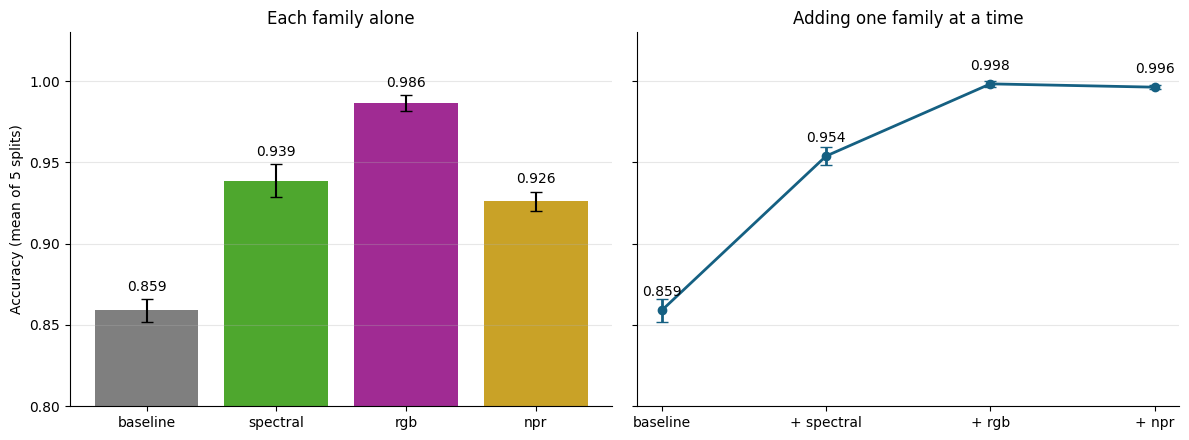

In [5]:
others = [name for name in families if name != "baseline"]
alone_labels = ["baseline"] + others
alone_keys = ["baseline"] + [f"{name} alone" for name in others]
steps = list(PROGRESSION_GROUPS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ax = axes[0]
bars = ax.bar(alone_labels, stability.loc[alone_keys, "mean"], yerr=stability.loc[alone_keys, "std"],
              color=[FAMILY_COLORS[name] for name in alone_labels], capsize=4)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set_title("Each family alone")
ax.set_ylabel("Accuracy (mean of 5 splits)")

ax = axes[1]
ax.errorbar(range(len(steps)), stability.loc[steps, "mean"], yerr=stability.loc[steps, "std"],
            marker="o", color=BLUE, capsize=4, lw=2)
for i, step in enumerate(steps):
    ax.annotate(f"{stability.loc[step, 'mean']:.3f}", (i, stability.loc[step, "mean"]),
                textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_xticks(range(len(steps)), steps)
ax.set_title("Adding one family at a time")

for ax in axes:
    ax.set_ylim(0.8, 1.03)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

*Every family beats the basic statistics on its own, RGB being the strongest. Adding RGB brings the accuracy close to 1.0, and NPR adds nothing more.*

### 4.2 Confusion matrices

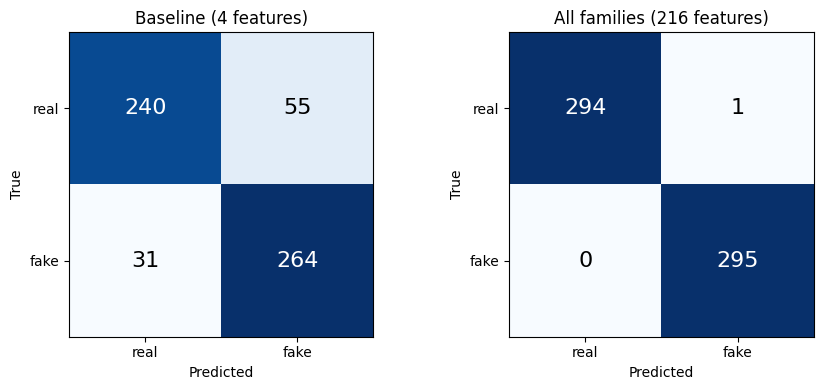

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, key, title in zip(axes, ["baseline", "+ npr"], ["Baseline (4 features)", "All families (216 features)"]):
    r = results.loc[key]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["real", "fake"])
    ax.set_yticks([0, 1], ["real", "fake"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
plt.tight_layout()
plt.show()

*The baseline mixes up real and fake in both directions. The full model makes almost no mistake on the test images.*

### 4.3 Score distributions

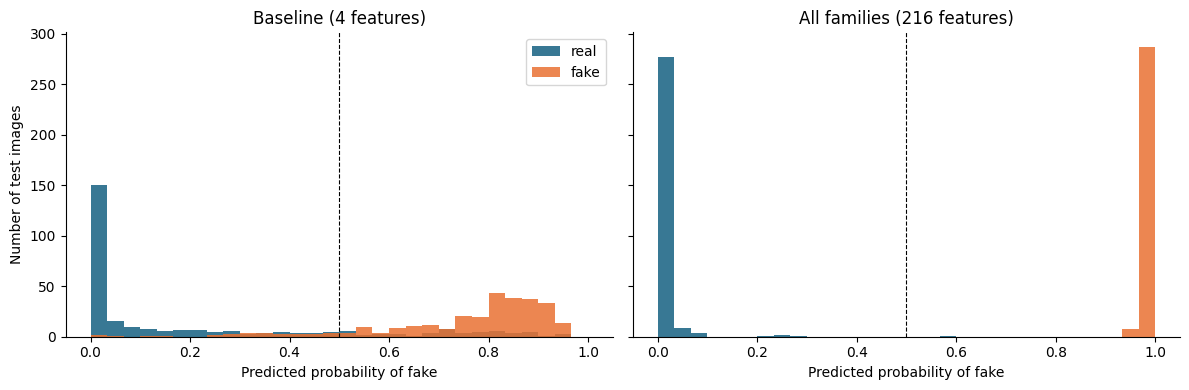

In [7]:
all_columns = [c for columns in families.values() for c in columns]
models = {"Baseline (4 features)": families["baseline"], "All families (216 features)": all_columns}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.linspace(0, 1, 31)
for ax, (title, columns) in zip(axes, models.items()):
    scores = predict_scores(train_logistic(train, columns), test, columns)
    ax.hist(scores[test["y"] == 0], bins=bins, color=BLUE, alpha=0.85, label="real")
    ax.hist(scores[test["y"] == 1], bins=bins, color=ORANGE, alpha=0.85, label="fake")
    ax.axvline(0.5, color="k", lw=0.8, ls="--")
    ax.set_title(title)
    ax.set_xlabel("Predicted probability of fake")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of test images")
axes[0].legend()
plt.tight_layout()
plt.show()

*With the baseline the two classes overlap around the threshold (dashed line). With all families they are pushed to the two ends, so the separation is not a close call.*

### 4.4 Most important features

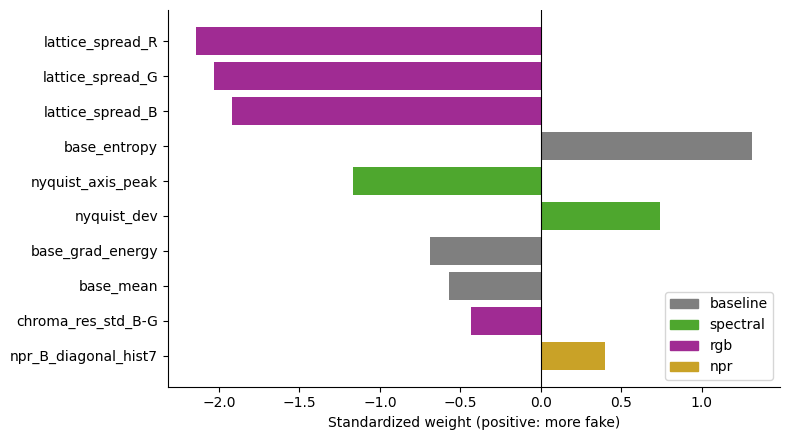

In [8]:
family_of = {column: name for name, columns in families.items() for column in columns}
weights = pd.Series(train_logistic(train, all_columns)[-1].coef_[0], index=all_columns)
top = weights.reindex(weights.abs().sort_values(ascending=False).index)[:10][::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=[FAMILY_COLORS[family_of[c]] for c in top.index])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Standardized weight (positive: more fake)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()], FAMILY_COLORS.keys(), loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

*The three `lattice_spread` features (the camera 2 × 2 grid, RGB family) dominate, followed by the entropy and the Nyquist points of the spectrum. Weights of correlated features should not be read one by one.*

## 5. Conclusions and limits
**Conclusions**
- Basic statistics alone already reach about 0.85 accuracy: real and fake images differ in content before any forensic analysis.
- Each family alone does better than the baseline: RGB 0.99, spectral 0.93, NPR 0.92.
- Adding spectral features to the baseline brings about 10 points; adding RGB then brings the accuracy to about 1.0; NPR adds nothing more.
- The families are complementary at first (each addition removes errors), but the camera-grid features of the RGB family almost suffice on their own.

**Limits**
- Real images are native-resolution crops of raw camera photos, fake images are full Midjourney images cropped at the centre. The camera traces are intact in the real images, so these scores describe this dataset and do not measure robustness (JPEG compression, resizing were not tested).
- 16 pairs were removed (completely white real crop); 984 pairs remain.
- The test set was used to compare the steps, but no choice or setting was tuned on it.
- The 180 NPR column names were written from the order of the extractor code.